# LAB1 - Bài 12 (Online Retail): Apriori, luật kết hợp và biểu đồ (bước 9-11)

**Họ tên:** Đinh Công Vinh Quang  
**MSSV:** 6451071061

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

HO_TEN, MSSV = "Đinh Công Vinh Quang", "6451071061"
print(f"{HO_TEN} - {MSSV}")
import time
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

Đinh Công Vinh Quang - 6451071061


In [2]:
# 1. Đọc dữ liệu
df = pd.read_excel("Online_Retail.xlsx")
print("Kích thước ban đầu:", df.shape)

# 2. Cắt ký tự thừa ở Description, xóa dòng không có InvoiceNo, đổi InvoiceNo về chuỗi
df["Description"] = df["Description"].str.strip()
df = df.dropna(axis=0, subset=["InvoiceNo"])
df["InvoiceNo"] = df["InvoiceNo"].astype("str")

# 3. Xóa hóa đơn tín dụng (InvoiceNo chứa 'C')
credit = df[df["InvoiceNo"].str.contains("C")]
df = df[~df["InvoiceNo"].str.contains("C")]
print("Số dòng hóa đơn tín dụng đã xóa:", len(credit), "| còn lại:", len(df))
# 5. Hóa đơn nước Anh, gom nhóm Quantity theo InvoiceNo và Description
def make_basket(data, country):
    return (data[data["Country"] == country]
            .groupby(["InvoiceNo", "Description"])["Quantity"].sum().unstack(fill_value=0))

# 7. Chuyển về hot/one-hot encoding: Quantity > 0 -> 1 (True), còn lại 0 (False)
def encode_units(x):
    return x > 0

basket = make_basket(df, "United Kingdom")                 # 6. mỗi dòng là một hóa đơn
basket_sets = encode_units(basket)
# 8. Xóa cột POSTAGE (cước phí)
if "POSTAGE" in basket_sets.columns:
    basket_sets = basket_sets.drop(columns=["POSTAGE"])
print("Ma trận hóa đơn x mặt hàng:", basket_sets.shape)

Kích thước ban đầu: (541909, 8)


Số dòng hóa đơn tín dụng đã xóa: 9288 | còn lại: 532621


Ma trận hóa đơn x mặt hàng: (18667, 4174)


In [3]:
# 9. Apriori với min_sup = 3%
frequent_itemsets = apriori(basket_sets, min_support=0.03, use_colnames=True)
frequent_itemsets["length"] = frequent_itemsets["itemsets"].apply(len)
print("Số tập phổ biến:", len(frequent_itemsets))
frequent_itemsets.sort_values("support", ascending=False).head(10)

Số tập phổ biến: 131


,support,itemsets,length
118,0.116034,frozenset({WHITE HANGING HEART T-LIGHT HOLDER}),1
52,0.103820,frozenset({JUMBO BAG RED RETROSPOT}),1
95,0.090266,frozenset({REGENCY CAKESTAND 3 TIER}),1
84,0.085391,frozenset({PARTY BUNTING}),1
69,0.074570,frozenset({LUNCH BAG RED RETROSPOT}),1
7,0.073445,frozenset({ASSORTED COLOUR BIRD ORNAMENT}),1
103,0.066481,frozenset({SET OF 3 CAKE TINS PANTRY DESIGN}),1
75,0.065302,frozenset({NATURAL SLATE HEART CHALKBOARD}),1
63,0.065142,frozenset({LUNCH BAG BLACK SKULL.}),1
35,0.062356,frozenset({HEART OF WICKER SMALL}),1


In [4]:
# 10. Luật kết hợp với min_conf = 50%
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.5)
print("Số luật:", len(rules))
rules[["antecedents", "consequents", "support", "confidence", "lift"]].head()

Số luật: 10


,antecedents,consequents,support,confidence,lift
0,frozenset({ALARM CLOCK BAKELIKE GREEN}),frozenset({ALARM CLOCK BAKELIKE RED}),0.030160,0.642694,12.900183
1,frozenset({ALARM CLOCK BAKELIKE RED}),frozenset({ALARM CLOCK BAKELIKE GREEN}),0.030160,0.605376,12.900183
2,frozenset({PINK REGENCY TEACUP AND SAUCER}),frozenset({GREEN REGENCY TEACUP AND SAUCER}),0.030910,0.820768,16.403939
3,frozenset({GREEN REGENCY TEACUP AND SAUCER}),frozenset({PINK REGENCY TEACUP AND SAUCER}),0.030910,0.617773,16.403939
4,frozenset({ROSES REGENCY TEACUP AND SAUCER}),frozenset({GREEN REGENCY TEACUP AND SAUCER}),0.037553,0.732497,14.639752


In [5]:
# đổi vế trái/phải từ frozenset sang chuỗi và in các luật
rules["antecedents"] = rules["antecedents"].apply(lambda s: ", ".join(sorted(s)))
rules["consequents"] = rules["consequents"].apply(lambda s: ", ".join(sorted(s)))
for _, r in rules.iterrows():
    print(f"{r['antecedents']}  =>  {r['consequents']}   (support={r['support']:.3f}, confidence={r['confidence']:.3f})")

ALARM CLOCK BAKELIKE GREEN  =>  ALARM CLOCK BAKELIKE RED   (support=0.030, confidence=0.643)
ALARM CLOCK BAKELIKE RED  =>  ALARM CLOCK BAKELIKE GREEN   (support=0.030, confidence=0.605)
PINK REGENCY TEACUP AND SAUCER  =>  GREEN REGENCY TEACUP AND SAUCER   (support=0.031, confidence=0.821)
GREEN REGENCY TEACUP AND SAUCER  =>  PINK REGENCY TEACUP AND SAUCER   (support=0.031, confidence=0.618)
ROSES REGENCY TEACUP AND SAUCER  =>  GREEN REGENCY TEACUP AND SAUCER   (support=0.038, confidence=0.732)
GREEN REGENCY TEACUP AND SAUCER  =>  ROSES REGENCY TEACUP AND SAUCER   (support=0.038, confidence=0.751)
JUMBO  BAG BAROQUE BLACK WHITE  =>  JUMBO BAG RED RETROSPOT   (support=0.031, confidence=0.626)
JUMBO BAG PINK POLKADOT  =>  JUMBO BAG RED RETROSPOT   (support=0.042, confidence=0.677)
JUMBO SHOPPER VINTAGE RED PAISLEY  =>  JUMBO BAG RED RETROSPOT   (support=0.035, confidence=0.580)
JUMBO STORAGE BAG SUKI  =>  JUMBO BAG RED RETROSPOT   (support=0.037, confidence=0.618)


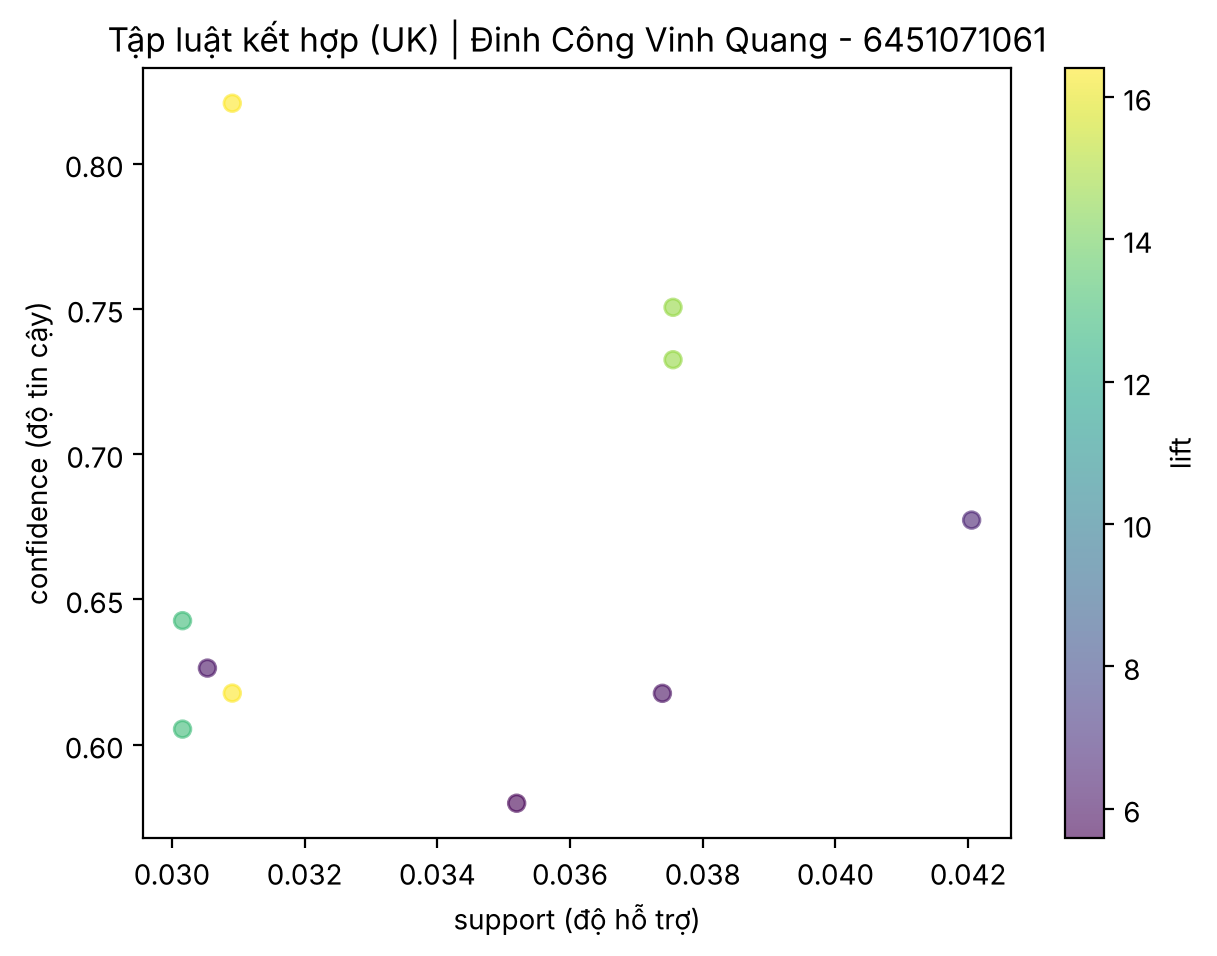

In [6]:
# 11. Biểu đồ phân tán độ hỗ trợ - độ tin cậy
plt.figure(figsize=(7, 5))
plt.scatter(rules["support"], rules["confidence"], alpha=0.6, c=rules["lift"], cmap="viridis")
plt.colorbar(label="lift")
plt.xlabel("support (độ hỗ trợ)"); plt.ylabel("confidence (độ tin cậy)")
plt.title(f"Tập luật kết hợp (UK) | {HO_TEN} - {MSSV}")
plt.show()